In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.special import ellipk, ellipj
from scipy.optimize import brentq
from IPython.display import Image, display
from pathlib import Path
from tempfile import TemporaryDirectory

plt.rcParams.update({"font.size": 10, "animation.embed_limit": 50})
g, l, mass = 9.81, 1.0, 1.0
omega = np.sqrt(g/l)
T0 = 2*np.pi/omega


def rhs(y, length=l, nonlinear=True):
    theta, velocity = y
    return np.array([velocity, -g/length*(np.sin(theta) if nonlinear else theta)])


def rk4_step(y, h, length=l, nonlinear=True):
    k1 = rhs(y, length, nonlinear)
    k2 = rhs(y + h*k1/2, length, nonlinear)
    k3 = rhs(y + h*k2/2, length, nonlinear)
    k4 = rhs(y + h*k3, length, nonlinear)
    return y + h*(k1 + 2*k2 + 2*k3 + k4)/6


def solve(amplitude, duration, h, method="RK4", nonlinear=True, length=l):
    n = int(np.ceil(duration/h))
    t = np.linspace(0, duration, n+1)
    h = t[1]-t[0]
    y = np.empty((n+1, 2))
    y[0] = [amplitude, 0.0]
    for i in range(n):
        if method == "RK4":
            y[i+1] = rk4_step(y[i], h, length, nonlinear)
        elif method == "Эйлер":
            y[i+1] = y[i] + h*rhs(y[i], length, nonlinear)
        else:
            raise ValueError(method)
    return t, y


def exact_linear(t, amplitude, length=l):
    w = np.sqrt(g/length)
    return np.array([amplitude*np.cos(w*t), -amplitude*w*np.sin(w*t)]).T


def exact_nonlinear(t, amplitude, length=l):
    k = np.sin(amplitude/2)
    w = np.sqrt(g/length)
    sn, cn, dn, ph = ellipj(ellipk(k*k)-w*np.asarray(t), k*k)
    return np.array([2*np.arcsin(k*sn), -2*k*w*cn]).T


def period_exact(amplitude, length=l):
    return 4*np.sqrt(length/g)*ellipk(np.sin(amplitude/2)**2)


def energy(y, nonlinear=True, length=l):
    theta, velocity = y.T
    kinetic = mass*length**2*velocity**2/2
    potential = mass*g*length*(1-np.cos(theta) if nonlinear else theta**2/2)
    return potential, kinetic


def period_numeric(amplitude, h):
    t, y = solve(amplitude, 1.1*period_exact(amplitude)/4, h)
    indices = np.flatnonzero((y[:-1, 0] > 0) & (y[1:, 0] <= 0))
    i = indices[0]
    dt = t[i+1]-t[i]
    def crossing(s):
        return ((2*s**3-3*s**2+1)*y[i, 0]
                +(s**3-2*s**2+s)*dt*y[i, 1]
                +(-2*s**3+3*s**2)*y[i+1, 0]
                +(s**3-s**2)*dt*y[i+1, 1])
    s = brentq(crossing, 0, 1)
    return 4*(t[i]+s*dt)

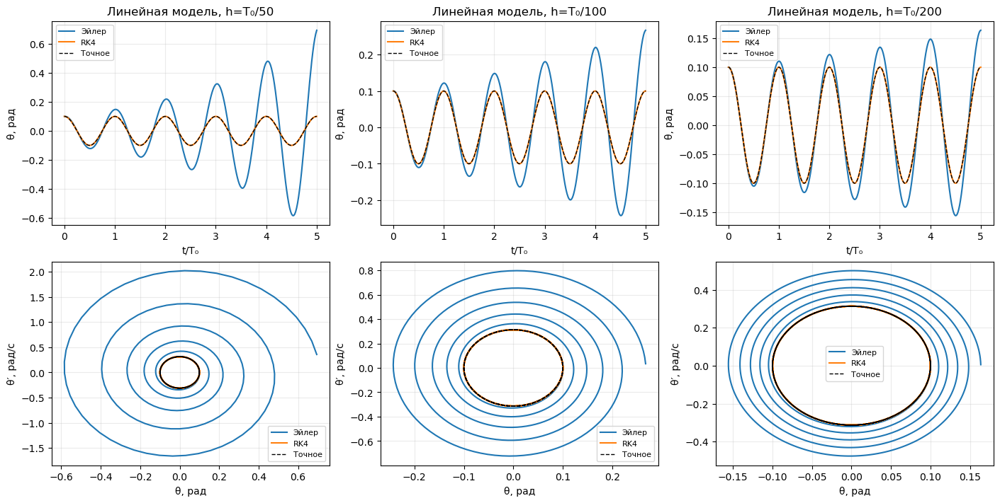

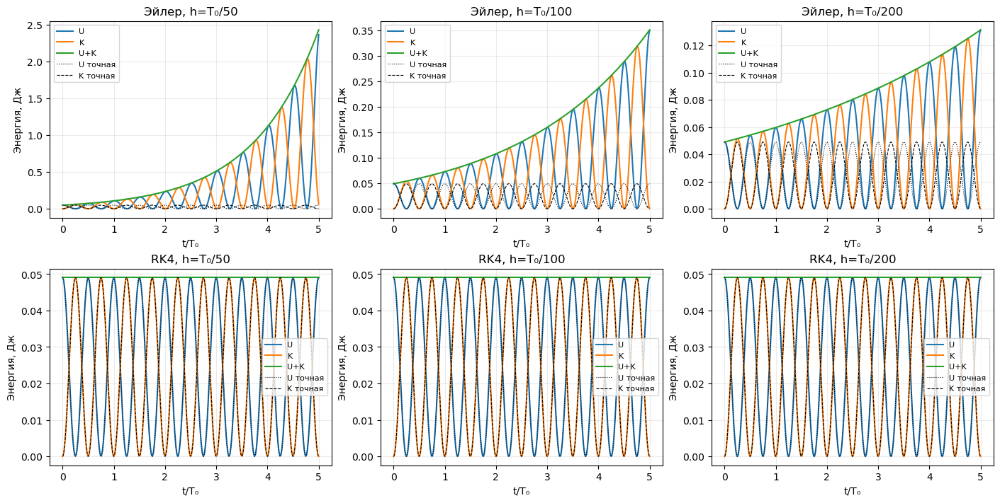

У Эйлера E[n+1]=(1+w²h²)E[n]: энергия и амплитуда растут при любом h>0.
Метод          h, с max |delta theta|, рад max |delta E/E0|
Эйлер      0.040121       5.941721e-01     4.848311e+01
Эйлер      0.020061       1.670364e-01     6.142894e+00
Эйлер      0.010030       6.367155e-02     1.679122e+00
RK4        0.040121       6.117776e-06     1.337655e-05
RK4        0.020061       3.853371e-07     4.228287e-07
RK4        0.010030       2.416405e-08     1.328443e-08


In [3]:
a_small = 0.1
linear_steps = [T0/50, T0/100, T0/200]
linear_results = {(method, h): solve(a_small, 5*T0, h, method, False)
                  for method in ["Эйлер", "RK4"] for h in linear_steps}
t_plot = np.linspace(0, 5*T0, 3001)
y_plot = exact_linear(t_plot, a_small)
fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
for col, h in enumerate(linear_steps):
    for method in ["Эйлер", "RK4"]:
        t, y = linear_results[method, h]
        axes[0, col].plot(t/T0, y[:, 0], label=method)
        axes[1, col].plot(y[:, 0], y[:, 1], label=method)
    axes[0, col].plot(t_plot/T0, y_plot[:, 0], "k--", lw=1, label="Точное")
    axes[1, col].plot(y_plot[:, 0], y_plot[:, 1], "k--", lw=1, label="Точное")
    axes[0, col].set(title=f"Линейная модель, h=T₀/{round(T0/h)}", xlabel="t/T₀", ylabel="θ, рад")
    axes[1, col].set(xlabel="θ, рад", ylabel="θ′, рад/с")
for ax in axes.flat:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True)
U_exact, K_exact = energy(y_plot, False)
for row, method in enumerate(["Эйлер", "RK4"]):
    for col, h in enumerate(linear_steps):
        t, y = linear_results[method, h]
        U, K = energy(y, False)
        ax = axes[row, col]
        ax.plot(t/T0, U, label="U")
        ax.plot(t/T0, K, label="K")
        ax.plot(t/T0, U+K, label="U+K")
        ax.plot(t_plot/T0, U_exact, "k:", lw=0.8, label="U точная")
        ax.plot(t_plot/T0, K_exact, "k--", lw=0.8, label="K точная")
        ax.set(title=f"{method}, h=T₀/{round(T0/h)}", xlabel="t/T₀", ylabel="Энергия, Дж")
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
plt.show()
print("У Эйлера E[n+1]=(1+w²h²)E[n]: энергия и амплитуда растут при любом h>0.")
print(f"{'Метод':<8} {'h, с':>10} {'max |delta theta|, рад':>18} {'max |delta E/E0|':>16}")
for (method, h), (t, y) in linear_results.items():
    U, K = energy(y, False)
    E = U+K
    err = np.max(np.abs(y[:, 0]-exact_linear(t, a_small)[:, 0]))
    print(f"{method:<8} {h:10.6f} {err:18.6e} {np.max(np.abs(E/E[0]-1)):16.6e}")

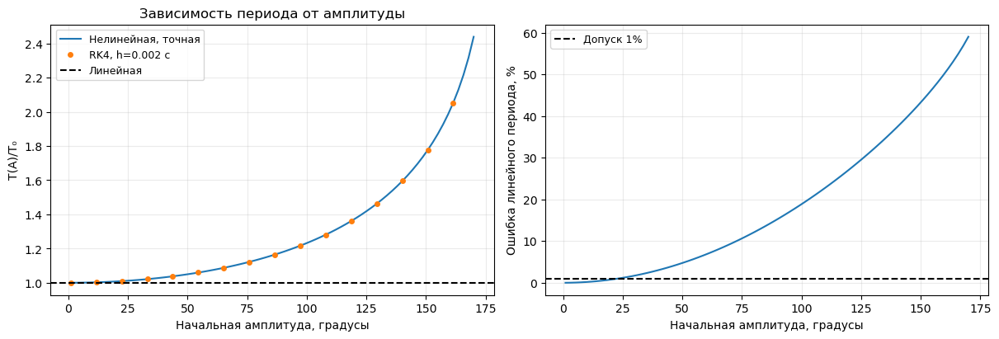

Период из RK4 определяется по первому переходу theta через ноль вниз: T=4t_cross.
Положение перехода уточняется кубической интерполяцией Эрмита по theta и thera′.
Формула T=4t_cross применима здесь благодаря старту из крайнего положения theta′(0)=0.
max |T_RK4−T_точный| = 4.616e-11 с
  A, град         T, с Ошибка Ttheta, %
        5    2.0070219         0.04759
       10    2.0098926         0.19036
       20    2.0214513         0.76107
       30    2.0409899         1.71109
       45    2.0862559         3.84369
       60    2.1528747         6.81916
       90    2.3678419        15.27869
      120    2.7540898        27.16045
      150    3.5350982        43.25287
      170    4.8935243        59.00569
Достаточная точность зависит от выбранного допуска. Ошибка здесь = (T(A)−T0)/T(A).
Для допуска 0.1% линейный период достаточно точен при |A| <= 7.25 grad.
Для допуска 1% линейный период достаточно точен при |A| <= 22.93 grad.
Для допуска 5% линейный период достаточно точен при |A| <= 

In [4]:
amplitudes_deg = np.linspace(1, 170, 80)
amplitudes = np.deg2rad(amplitudes_deg)
periods_exact = period_exact(amplitudes)
periods_numeric = np.array([period_numeric(a, 0.002) for a in amplitudes])
period_error = (periods_exact-T0)/periods_exact
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(amplitudes_deg, periods_exact/T0, label="Нелинейная, точная")
axes[0].plot(amplitudes_deg[::5], periods_numeric[::5]/T0, "o", ms=4, label="RK4, h=0.002 с")
axes[0].axhline(1, color="black", ls="--", label="Линейная")
axes[0].set(xlabel="Начальная амплитуда, градусы", ylabel="T(A)/T₀", title="Зависимость периода от амплитуды")
axes[1].plot(amplitudes_deg, 100*period_error)
axes[1].axhline(1, color="black", ls="--", label="Допуск 1%")
axes[1].set(xlabel="Начальная амплитуда, градусы", ylabel="Ошибка линейного периода, %")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
plt.show()
print("Период из RK4 определяется по первому переходу theta через ноль вниз: T=4t_cross.")
print("Положение перехода уточняется кубической интерполяцией Эрмита по theta и thera′.")
print("Формула T=4t_cross применима здесь благодаря старту из крайнего положения theta′(0)=0.")
print(f"max |T_RK4−T_точный| = {np.max(np.abs(periods_numeric-periods_exact)):.3e} с")
print(f"{'A, град':>9} {'T, с':>12} {'Ошибка Ttheta, %':>15}")
for deg in [5, 10, 20, 30, 45, 60, 90, 120, 150, 170]:
    Tp = period_exact(np.deg2rad(deg))
    print(f"{deg:9.0f} {Tp:12.7f} {100*(Tp-T0)/Tp:15.5f}")
print("Достаточная точность зависит от выбранного допуска. Ошибка здесь = (T(A)−T0)/T(A).")
for tolerance in [0.001, 0.01, 0.05]:
    threshold = brentq(lambda a: 1-T0/period_exact(a)-tolerance, 1e-7, np.pi-1e-7)
    print(f"Для допуска {100*tolerance:g}% линейный период достаточно точен при |A| <= {np.rad2deg(threshold):.2f} grad.")
print("При A<<1 рад: T/T0=1+A^2/16+11A^4/3072+…; A выражена в радианах.")
print("Линейная модель занижает период. Точность периода не гарантирует совпадение фаз на длинном интервале.")

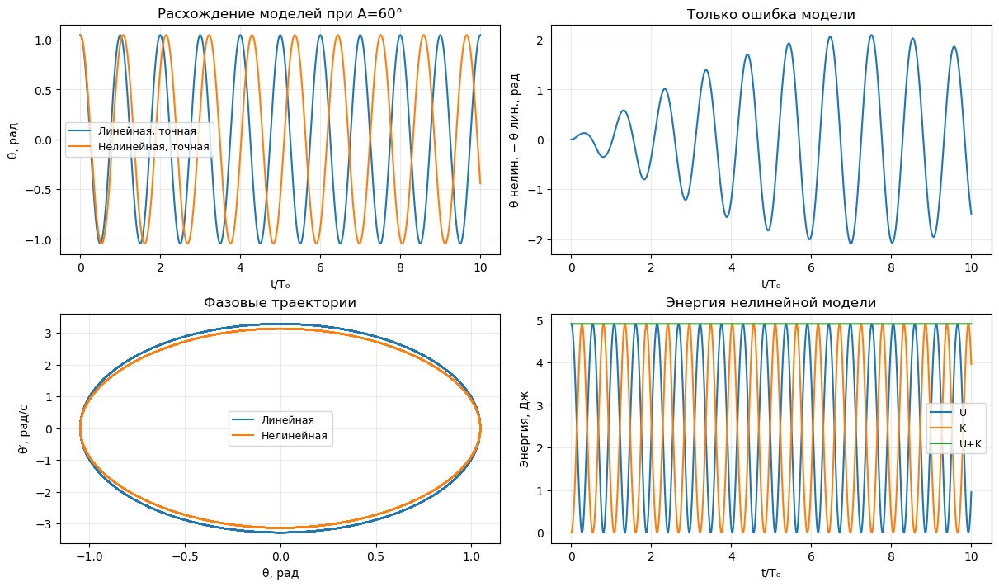

A=60 grad: T0=2.00606668 с, T нелин.=2.15287467 с; ошибка периода=6.819%.


In [5]:
a_chosen = np.deg2rad(60)
T_chosen = period_exact(a_chosen)
duration = 10*T0
t_dense = np.linspace(0, duration, 6001)
y_linear = exact_linear(t_dense, a_chosen)
y_nonlinear = exact_nonlinear(t_dense, a_chosen)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
axes[0, 0].plot(t_dense/T0, y_linear[:, 0], label="Линейная, точная")
axes[0, 0].plot(t_dense/T0, y_nonlinear[:, 0], label="Нелинейная, точная")
axes[0, 0].set(xlabel="t/T₀", ylabel="θ, рад", title="Расхождение моделей при A=60°")
axes[0, 1].plot(t_dense/T0, y_nonlinear[:, 0]-y_linear[:, 0])
axes[0, 1].set(xlabel="t/T₀", ylabel="θ нелин. − θ лин., рад", title="Только ошибка модели")
axes[1, 0].plot(y_linear[:, 0], y_linear[:, 1], label="Линейная")
axes[1, 0].plot(y_nonlinear[:, 0], y_nonlinear[:, 1], label="Нелинейная")
axes[1, 0].set(xlabel="θ, рад", ylabel="θ′, рад/с", title="Фазовые траектории")
U, K = energy(y_nonlinear)
axes[1, 1].plot(t_dense/T0, U, label="U")
axes[1, 1].plot(t_dense/T0, K, label="K")
axes[1, 1].plot(t_dense/T0, U+K, label="U+K")
axes[1, 1].set(xlabel="t/T₀", ylabel="Энергия, Дж", title="Энергия нелинейной модели")
for ax in axes.flat:
    ax.grid(alpha=0.25)
for ax in [axes[0, 0], axes[1, 0], axes[1, 1]]:
    ax.legend(fontsize=9)
plt.show()
print(f"A=60 grad: T0={T0:.8f} с, T нелин.={T_chosen:.8f} с; ошибка периода={100*(T_chosen-T0)/T_chosen:.3f}%.")

    h, с max |delta theta|, рад    |delta T|, с  max |delta E/E0|
   0.040       3.940112e-05    2.843265e-06      1.903242e-05
   0.020       3.839756e-06    1.753667e-07      6.027809e-07
   0.010       2.855657e-07    1.091854e-08      1.984541e-08
   0.005       1.928509e-08    7.028427e-10      6.806324e-10


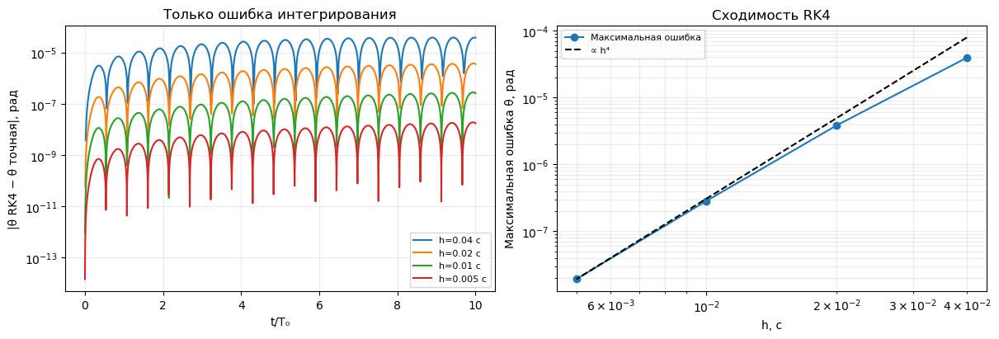

Оценки порядка при уменьшении шага вдвое: [3.359 3.749 3.888]
На конечных шагах оценки отличаются от 4, а при уточнении сетки они приближаются к порядку РК4.
Уменьшение шага снижает ошибку РК4, но не устраняет расхождение линейной и нелинейной моделей.


In [6]:
nonlinear_steps = [0.04, 0.02, 0.01, 0.005]
nonlinear_results = {h: solve(a_chosen, duration, h) for h in nonlinear_steps}
errors = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
print(f"{'h, с':>8} {'max |delta theta|, рад':>18} {'|delta T|, с':>15} {'max |delta E/E0|':>17}")
for h, (t, y) in nonlinear_results.items():
    theta_error = np.abs(y[:, 0]-exact_nonlinear(t, a_chosen)[:, 0])
    U, K = energy(y)
    E = U+K
    errors.append(np.max(theta_error))
    T_num = period_numeric(a_chosen, h)
    print(f"{h:8.3f} {errors[-1]:18.6e} {abs(T_num-T_chosen):15.6e} {np.max(np.abs(E/E[0]-1)):17.6e}")
    axes[0].semilogy(t/T0, np.where(theta_error>0, theta_error, np.nan), label=f"h={h} с")
axes[0].set(xlabel="t/T₀", ylabel="|θ RK4 − θ точная|, рад", title="Только ошибка интегрирования")
axes[1].loglog(nonlinear_steps, errors, "o-", label="Максимальная ошибка")
axes[1].loglog(nonlinear_steps, errors[-1]*(np.array(nonlinear_steps)/nonlinear_steps[-1])**4, "k--", label="∝ h⁴")
axes[1].set(xlabel="h, с", ylabel="Максимальная ошибка θ, рад", title="Сходимость RK4")
for ax in axes:
    ax.grid(alpha=0.25, which="both")
    ax.legend(fontsize=8)
plt.show()
print("Оценки порядка при уменьшении шага вдвое:", np.round(np.log2(np.array(errors[:-1])/errors[1:]), 3))
print("На конечных шагах оценки отличаются от 4, а при уточнении сетки они приближаются к порядку РК4.")
print("Уменьшение шага снижает ошибку РК4, но не устраняет расхождение линейной и нелинейной моделей.")

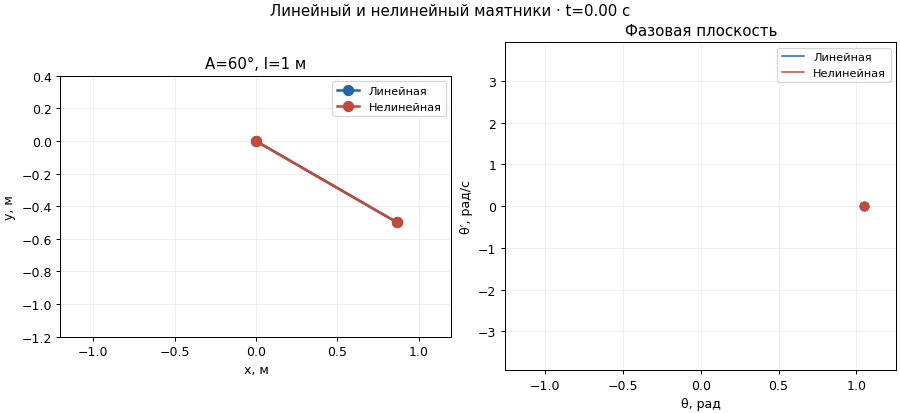

In [7]:
def animation_image(animation):
    animation._fig.canvas.draw()
    animation._fig.set_layout_engine(None)
    with TemporaryDirectory() as directory:
        path = Path(directory)/"animation.gif"
        animation.save(path, writer=PillowWriter(fps=fps), dpi=90)
        return Image(data=path.read_bytes(), format="gif")

fps = 20

anim_duration = 6*T0
t_sim, y_sim = solve(a_chosen, anim_duration, 0.002)
t_frames = np.linspace(0, anim_duration, round(anim_duration*fps)+1)
y_non_frames = np.column_stack([np.interp(t_frames, t_sim, y_sim[:, j]) for j in range(2)])
y_lin_frames = exact_linear(t_frames, a_chosen)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), constrained_layout=True)
axes[0].set(xlim=(-1.2, 1.2), ylim=(-1.2, 0.4), xlabel="x, м", ylabel="y, м", title="A=60°, l=1 м")
axes[0].set_aspect("equal")
axes[0].plot(0, 0, "ko", ms=4)
axes[1].set(xlim=(-1.2*a_chosen, 1.2*a_chosen), ylim=(-1.2*omega*a_chosen, 1.2*omega*a_chosen),
            xlabel="θ, рад", ylabel="θ′, рад/с", title="Фазовая плоскость")
rods, traces, points = [], [], []
for label, color in [("Линейная", "#2166ac"), ("Нелинейная", "#c34a36")]:
    rod, = axes[0].plot([], [], "o-", color=color, lw=2, ms=8, label=label)
    trace, = axes[1].plot([], [], color=color, lw=1.2, label=label)
    point, = axes[1].plot([], [], "o", color=color, ms=7)
    rods.append(rod)
    traces.append(trace)
    points.append(point)
for ax in axes:
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)
clock = fig.suptitle("t=0 с")





def update_comparison(i):
    for j, y in enumerate([y_lin_frames, y_non_frames]):
        theta = y[i, 0]
        rods[j].set_data([0, l*np.sin(theta)], [0, -l*np.cos(theta)])
        traces[j].set_data(y[:i+1, 0], y[:i+1, 1])
        points[j].set_data([y[i, 0]], [y[i, 1]])
    clock.set_text(f"Линейный и нелинейный маятники · t={t_frames[i]:.2f} с")
    return rods + traces + points + [clock]

animation_comparison = FuncAnimation(fig, update_comparison, frames=len(t_frames), interval=1000/fps, blit=False)
display(animation_image(animation_comparison))
plt.close(fig)

Ансамбль разной длины: нелинейные модели, одинаковый начальный угол 20 grad.
wi=0.25·ni, ni=10,…,19; li=g/wi^2.
Фактические частоты DELTA_i=wi/[2K(sin^2(A/2))/Pi] также соизмеримы: DELTA_i/DELTA_j=ni/nj.
Общее возвращение в начальное состояние ожидается через 25.325485 с.
Длины, м: [1.5696 1.2972 1.09   0.9288 0.8008 0.6976 0.6131 0.5431 0.4844 0.4348]


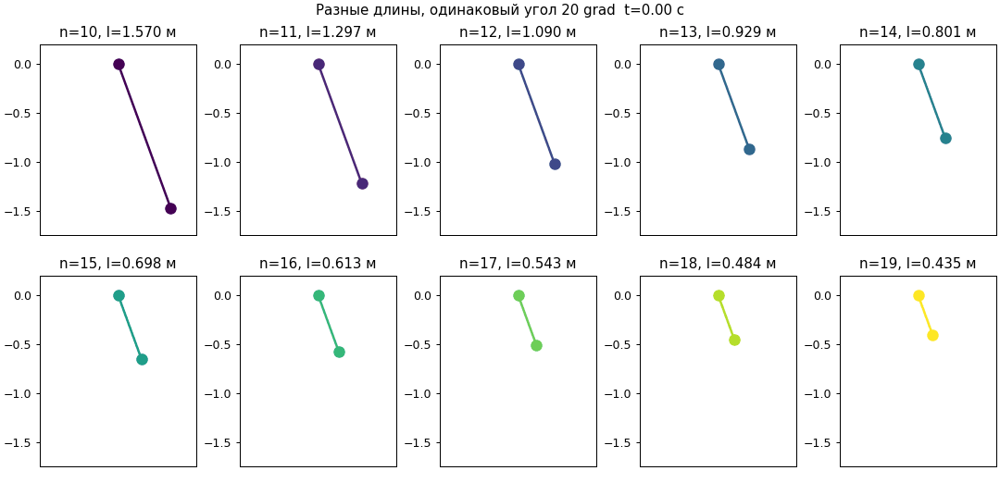

In [8]:
harmonics = np.arange(10, 20)
base_frequency = 0.25
frequencies = base_frequency*harmonics
lengths = g/frequencies**2
common_amplitude = np.deg2rad(20)
period_factor = 2*ellipk(np.sin(common_amplitude/2)**2)/np.pi
sync_time = 2*np.pi*period_factor/base_frequency
t_ensemble = np.linspace(0, sync_time, round(sync_time*fps)+1)
angles_lengths = []
for length in lengths:
    t, y = solve(common_amplitude, sync_time, 0.002, length=length)
    angles_lengths.append(np.interp(t_ensemble, t, y[:, 0]))
angles_lengths = np.array(angles_lengths)
print("Ансамбль разной длины: нелинейные модели, одинаковый начальный угол 20 grad.")
print("wi=0.25·ni, ni=10,…,19; li=g/wi^2.")
print("Фактические частоты DELTA_i=wi/[2K(sin^2(A/2))/Pi] также соизмеримы: DELTA_i/DELTA_j=ni/nj.")
print(f"Общее возвращение в начальное состояние ожидается через {sync_time:.6f} с.")
print("Длины, м:", np.round(lengths, 4))

fig, axes = plt.subplots(2, 5, figsize=(12, 5.8), constrained_layout=True)
ensemble_rods = []
for i, ax in enumerate(axes.flat):
    ax.set(xlim=(-0.8, 0.8), ylim=(-1.75, 0.2), title=f"n={harmonics[i]}, l={lengths[i]:.3f} м")
    ax.set_aspect("equal")
    ax.plot(0, 0, "ko", ms=3)
    rod, = ax.plot([], [], "o-", color=plt.cm.viridis(i/9), lw=2, ms=9)
    ensemble_rods.append(rod)
    ax.set_xticks([])
    ax.set_yticks([-1.5, -1.0, -0.5, 0])
clock_lengths = fig.suptitle("Ансамбль разной длины · t=0 с")

def update_lengths(j):
    for i, rod in enumerate(ensemble_rods):
        theta = angles_lengths[i, j]
        rod.set_data([0, lengths[i]*np.sin(theta)], [0, -lengths[i]*np.cos(theta)])
    clock_lengths.set_text(f"Разные длины, одинаковый угол 20 grad  t={t_ensemble[j]:.2f} с")
    return ensemble_rods + [clock_lengths]

animation_lengths = FuncAnimation(fig, update_lengths, frames=len(t_ensemble), interval=1000/fps, blit=False)
display(animation_image(animation_lengths))
plt.close(fig)

Ансамбль одинаковой длины: 10 нелинейных маятников, l=1 м, A=10 gradus,20 gradus,…,100 gradus.
Все отпущены одновременно с нулевой скоростью. Разные периоды приводят к расхождению фаз.
Периоды, с: [2.0099 2.0215 2.041  2.0689 2.1059 2.1529 2.211  2.2819 2.3678 2.4719]


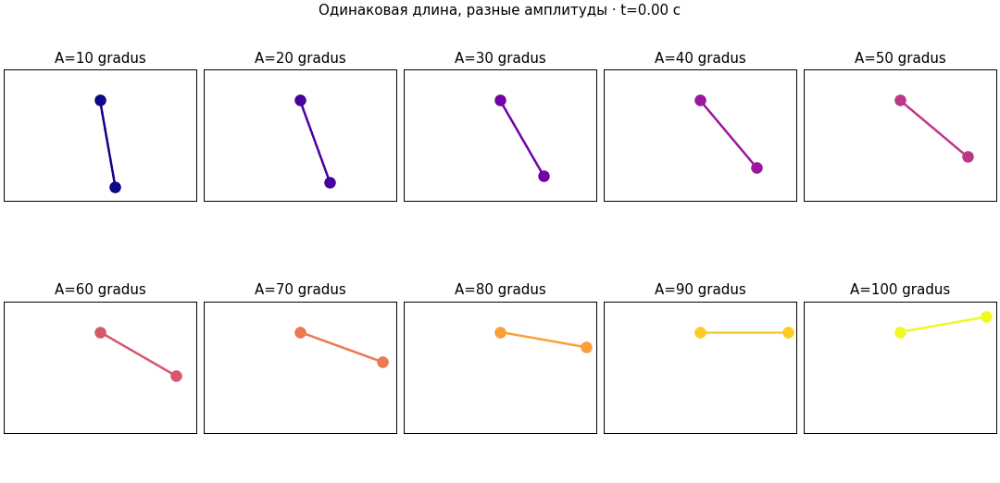

In [9]:
amplitudes_ensemble_deg = np.linspace(10, 100, 10)
amplitudes_ensemble = np.deg2rad(amplitudes_ensemble_deg)
duration_equal = 12*T0
t_equal = np.linspace(0, duration_equal, round(duration_equal*fps)+1)
angles_amplitudes = []
for amplitude in amplitudes_ensemble:
    t, y = solve(amplitude, duration_equal, 0.002)
    angles_amplitudes.append(np.interp(t_equal, t, y[:, 0]))
angles_amplitudes = np.array(angles_amplitudes)
print("Ансамбль одинаковой длины: 10 нелинейных маятников, l=1 м, A=10 gradus,20 gradus,…,100 gradus.")
print("Все отпущены одновременно с нулевой скоростью. Разные периоды приводят к расхождению фаз.")
print("Периоды, с:", np.round(period_exact(amplitudes_ensemble), 4))

fig, axes = plt.subplots(2, 5, figsize=(12, 5.8), constrained_layout=True)
amplitude_rods = []
for i, ax in enumerate(axes.flat):
    ax.set(xlim=(-1.1, 1.1), ylim=(-1.15, 0.35), title=f"A={amplitudes_ensemble_deg[i]:.0f} gradus")
    ax.set_aspect("equal")
    ax.plot(0, 0, "ko", ms=3)
    rod, = ax.plot([], [], "o-", color=plt.cm.plasma(i/9), lw=2, ms=9)
    amplitude_rods.append(rod)
    ax.set_xticks([])
    ax.set_yticks([])
clock_amplitudes = fig.suptitle("Ансамбль одинаковой длины · t=0 с")

def update_amplitudes(j):
    for i, rod in enumerate(amplitude_rods):
        theta = angles_amplitudes[i, j]
        rod.set_data([0, l*np.sin(theta)], [0, -l*np.cos(theta)])
    clock_amplitudes.set_text(f"Одинаковая длина, разные амплитуды · t={t_equal[j]:.2f} с")
    return amplitude_rods + [clock_amplitudes]

animation_amplitudes = FuncAnimation(fig, update_amplitudes, frames=len(t_equal), interval=1000/fps, blit=False)
display(animation_image(animation_amplitudes))
plt.close(fig)